# 07. Transfer Learning and Fine-Tuning with PyTorch

Transfer learning reuses representations learned by a model on a large source dataset and adapts them to a new task. This notebook introduces pretrained CNNs, frozen feature extractors, fine-tuning, learning-rate choices, evaluation, and practical safeguards.

**Learning objectives**
- Explain the difference between feature extraction and fine-tuning.
- Load a pretrained ResNet-18 when pretrained weights are available.
- Replace the final classification layer for a new task.
- Train only the new head, then optionally fine-tune selected backbone layers.
- Compare training and validation metrics and inspect predictions.
- Understand what to do when data or pretrained weights cannot be downloaded.

**Important:** The notebook tries to use pretrained ImageNet weights and CIFAR-10. If either download is unavailable, it falls back to a small synthetic dataset and/or an untrained ResNet-18 so the code path remains demonstrable. That fallback demonstrates the workflow, but it is **not evidence of successful pretrained transfer learning**.

## 1. Imports, reproducibility, and device

PyTorch models and batches should be placed on the same device. The code selects CUDA when available and otherwise uses the CPU. Training a ResNet-18 on CPU can be slow, so the example uses small subsets and a limited number of epochs.

In [1]:
import random
import copy
import time
import numpy as np
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import DataLoader, Subset, random_split, TensorDataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch version:", torch.__version__)
print("Device:", device)

PyTorch version: 2.5.1+cu121
Device: cuda


## 2. What is transfer learning?

A model trained on a large source dataset often learns reusable visual features:
- Early layers may respond to edges, colors, and simple textures.
- Middle layers may respond to shapes and parts.
- Later layers are more task-specific.

Transfer learning adapts these representations to a target dataset. Two common strategies are:

1. **Feature extraction:** freeze the pretrained backbone and train only a new classification head.
2. **Fine-tuning:** unfreeze some or all backbone layers and continue training with a small learning rate.

A pretrained model is a starting point, not a guarantee of good performance. Results depend on dataset size, similarity to the source domain, preprocessing, and evaluation design.

## 3. Imports from torchvision

`torchvision` provides common datasets, image transforms, and model architectures. The next cell checks whether it is available. If not, the notebook stops with a clear message because the main ResNet example depends on it.

In [2]:
try:
    from torchvision import datasets, transforms, models
    TORCHVISION_AVAILABLE = True
except Exception as exc:
    TORCHVISION_AVAILABLE = False
    print("torchvision could not be imported:", repr(exc))
    print("Install a torchvision build compatible with your PyTorch version, then rerun this cell.")

if not TORCHVISION_AVAILABLE:
    raise RuntimeError(
        "This notebook requires torchvision for ResNet-18 and image datasets. "
        "Install a compatible torchvision version before continuing."
    )

## 4. Load a pretrained ResNet-18

The weights enum is the recommended way to request pretrained weights in modern torchvision. Downloading weights may fail in restricted or offline environments. We record whether pretrained weights were actually loaded so later conclusions remain honest.

In [3]:
pretrained_loaded = False
weights = None

try:
    # Request the standard ImageNet-pretrained ResNet-18 weights.
    weights = models.ResNet18_Weights.DEFAULT
    model = models.resnet18(weights=weights)
    pretrained_loaded = True
    print("Loaded ImageNet-pretrained ResNet-18.")
except Exception as exc:
    # Continue with randomly initialized weights if download/loading fails.
    print("Could not load pretrained weights:", repr(exc))
    print("Using randomly initialized ResNet-18 for workflow demonstration.")
    model = models.resnet18(weights=None)

print("Pretrained weights loaded:", pretrained_loaded)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\mobin/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


Could not load pretrained weights: URLError(gaierror(11001, 'getaddrinfo failed'))
Using randomly initialized ResNet-18 for workflow demonstration.
Pretrained weights loaded: False


## 5. Choose transforms that match the model

Pretrained ImageNet models expect three-channel RGB images and the normalization used during pretraining. The weights object provides the recommended evaluation transform. For training, we add a small random crop and horizontal flip, then apply the same normalization.

If pretrained weights could not be loaded, we still use a consistent image size and normalization for this demonstration.

In [4]:
IMAGE_SIZE = 224
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

print("Input size:", IMAGE_SIZE, "x", IMAGE_SIZE)
print("Expected tensor shape per image: (3, 224, 224)")

Input size: 224 x 224
Expected tensor shape per image: (3, 224, 224)


## 6. Load CIFAR-10 or create a fallback dataset

CIFAR-10 has 10 classes and RGB images. We use small subsets to keep this teaching example manageable. If dataset download fails, a synthetic dataset is created. Synthetic images are only a coding fallback and should not be used to draw conclusions about real-world generalization.

In [5]:
class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]
dataset_source = "synthetic fallback"

try:
    train_augmented = datasets.CIFAR10(
        root="./data", train=True, download=True, transform=train_transform
    )
    train_evaluation = datasets.CIFAR10(
        root="./data", train=True, download=True, transform=eval_transform
    )
    test_dataset = datasets.CIFAR10(
        root="./data", train=False, download=True, transform=eval_transform
    )
    dataset_source = "CIFAR-10"
except Exception as exc:
    print("CIFAR-10 download failed:", repr(exc))
    print("Creating a synthetic RGB dataset for code demonstration.")

    def make_synthetic_dataset(n_items):
        # Each label gets a simple color/pattern cue; this is not realistic data.
        images = torch.rand(n_items, 3, 64, 64) * 0.15
        labels = torch.randint(0, 10, (n_items,))
        for i, label in enumerate(labels):
            channel = int(label) % 3
            images[i, channel, 8:56, 8 + (int(label) % 8):24 + (int(label) % 8)] += 0.7
            images[i] += 0.04 * torch.randn_like(images[i])
        images = images.clamp(0, 1)
        return TensorDataset(images, labels)

    # Apply the same normalization and resize expected by the model.
    class TensorImageTransformDataset(torch.utils.data.Dataset):
        def __init__(self, base_dataset, transform):
            self.base_dataset = base_dataset
            self.transform = transform
        def __len__(self):
            return len(self.base_dataset)
        def __getitem__(self, idx):
            image, label = self.base_dataset[idx]
            # Convert a tensor image to PIL so torchvision transforms can resize it.
            from torchvision.transforms.functional import to_pil_image
            image = to_pil_image(image)
            return self.transform(image), label

    raw_train = make_synthetic_dataset(1200)
    raw_test = make_synthetic_dataset(300)
    train_augmented = TensorImageTransformDataset(raw_train, train_transform)
    train_evaluation = TensorImageTransformDataset(raw_train, eval_transform)
    test_dataset = TensorImageTransformDataset(raw_test, eval_transform)

print("Dataset source:", dataset_source)
print("Pretrained weights loaded:", pretrained_loaded)

CIFAR-10 download failed: URLError(gaierror(11001, 'getaddrinfo failed'))
Creating a synthetic RGB dataset for code demonstration.
Dataset source: synthetic fallback
Pretrained weights loaded: False


## 7. Create small, reproducible subsets

The example uses a subset of the available training data to reduce runtime. We use one transformed view with augmentation for training and a deterministic transformed view for validation. Both views refer to the same underlying training examples, but only the training view applies random augmentation.

In [6]:
# Use at most 2,000 training examples and 500 test examples for a compact demo.
train_count = min(2000, len(train_augmented))
test_count = min(500, len(test_dataset))

generator = torch.Generator().manual_seed(SEED)
selected_train_indices = torch.randperm(len(train_augmented), generator=generator)[:train_count].tolist()
selected_test_indices = torch.randperm(len(test_dataset), generator=generator)[:test_count].tolist()

# Split selected indices into train and validation portions.
split_point = int(0.85 * train_count)
train_indices = selected_train_indices[:split_point]
val_indices = selected_train_indices[split_point:]

train_dataset = Subset(train_augmented, train_indices)
val_dataset = Subset(train_evaluation, val_indices)
test_dataset_small = Subset(test_dataset, selected_test_indices)

BATCH_SIZE = 16
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset_small, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"Train: {len(train_dataset)} | Validation: {len(val_dataset)} | Test: {len(test_dataset_small)}")

Train: 1020 | Validation: 180 | Test: 300


## 8. Inspect the transformed data

The normalization step changes pixel values, so the displayed image must be denormalized for visualization. This helper reverses ImageNet normalization for plotting only; it does not modify the data used by the model.

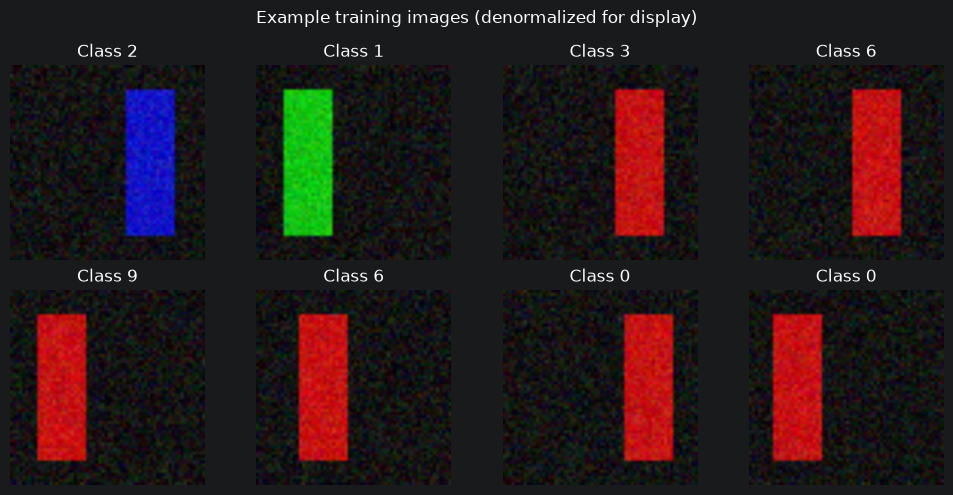

In [7]:
def denormalize_image(tensor_image):
    # Convert normalized CHW tensor to a displayable HWC NumPy array.
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    image = tensor_image.cpu() * std + mean
    return image.clamp(0, 1).permute(1, 2, 0).numpy()

images, labels = next(iter(train_loader))
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for i, ax in enumerate(axes.flat):
    if i < len(images):
        ax.imshow(denormalize_image(images[i]))
        label = int(labels[i])
        ax.set_title(class_names[label] if dataset_source == "CIFAR-10" else f"Class {label}")
    ax.axis("off")
plt.suptitle("Example training images (denormalized for display)")
plt.tight_layout()
plt.show()

## 9. Replace the classification head

ResNet-18's original final layer predicts 1,000 ImageNet classes. For CIFAR-10, we replace it with a layer that outputs 10 logits. `in_features` lets us inspect the number of input features expected by the old head rather than hard-coding it.

In [8]:
num_classes = 10
in_features = model.fc.in_features
model.fc = nn.Linear(in_features, num_classes)
model = model.to(device)

print("Input features to new head:", in_features)
print("New classifier:", model.fc)

Input features to new head: 512
New classifier: Linear(in_features=512, out_features=10, bias=True)


## 10. Strategy A — freeze the backbone

Freezing sets `requires_grad=False` for backbone parameters. Only the new classification head will be updated. This is often a good first baseline when the dataset is small and the pretrained domain is reasonably similar.

In [9]:
# Freeze every parameter in the model.
for parameter in model.parameters():
    parameter.requires_grad = False

# Unfreeze only the newly created classification head.
for parameter in model.fc.parameters():
    parameter.requires_grad = True

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())
print(f"Trainable parameters: {trainable_params:,} / {total_params:,} ({trainable_params / total_params:.2%})")

Trainable parameters: 5,130 / 11,181,642 (0.05%)


## 11. Training and evaluation functions

The training function performs gradient updates only when an optimizer is supplied. During validation and testing, it disables gradient tracking. The loss is cross-entropy over raw logits, and accuracy is computed from the highest-scoring class.

In [10]:
criterion = nn.CrossEntropyLoss()

def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)

    running_loss = 0.0
    correct = 0
    total = 0

    for batch_images, batch_labels in loader:
        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits = model(batch_images)
            loss = criterion(logits, batch_labels)

            if training:
                loss.backward()
                optimizer.step()

        batch_size = batch_labels.size(0)
        running_loss += loss.item() * batch_size
        correct += (logits.argmax(dim=1) == batch_labels).sum().item()
        total += batch_size

    return running_loss / total, correct / total

## 12. Train the new head

The head can often adapt faster than the backbone, so use a learning rate appropriate for a newly initialized layer. A short run is enough to demonstrate the workflow; real projects need systematic tuning and adequate validation.

In [11]:
HEAD_EPOCHS = 2
head_optimizer = torch.optim.AdamW(
    (p for p in model.parameters() if p.requires_grad),
    lr=1e-3,
    weight_decay=1e-4
)

history = {
    "head_train_loss": [], "head_val_loss": [],
    "head_train_acc": [], "head_val_acc": []
}

for epoch in range(HEAD_EPOCHS):
    start_time = time.time()
    train_loss, train_acc = run_epoch(model, train_loader, criterion, head_optimizer)
    val_loss, val_acc = run_epoch(model, val_loader, criterion)

    history["head_train_loss"].append(train_loss)
    history["head_val_loss"].append(val_loss)
    history["head_train_acc"].append(train_acc)
    history["head_val_acc"].append(val_acc)

    print(
        f"Head epoch {epoch + 1}/{HEAD_EPOCHS} | "
        f"train loss={train_loss:.4f}, acc={train_acc:.3f} | "
        f"val loss={val_loss:.4f}, acc={val_acc:.3f} | "
        f"{time.time() - start_time:.1f}s"
    )

Head epoch 1/2 | train loss=2.0908, acc=0.293 | val loss=1.7211, acc=0.411 | 4.3s
Head epoch 2/2 | train loss=1.5931, acc=0.604 | val loss=1.2949, acc=0.717 | 3.8s


## 13. Strategy B — fine-tune the last ResNet block

Fine-tuning allows selected pretrained weights to adapt to the target domain. A common strategy is to unfreeze the last residual block and the classifier while keeping early layers frozen. Use a smaller learning rate for pretrained layers than for the new head to reduce destructive updates.

In [12]:
# Keep the early backbone frozen.
for parameter in model.parameters():
    parameter.requires_grad = False

# Unfreeze the last residual block and the classification head.
for parameter in model.layer4.parameters():
    parameter.requires_grad = True
for parameter in model.fc.parameters():
    parameter.requires_grad = True

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable parameters after unfreezing layer4: {trainable_params:,}")

fine_tune_optimizer = torch.optim.AdamW(
    [
        {"params": model.layer4.parameters(), "lr": 1e-5},
        {"params": model.fc.parameters(), "lr": 1e-4},
    ],
    weight_decay=1e-4
)

Trainable parameters after unfreezing layer4: 8,398,858


## 14. Fine-tune and track metrics

A very small learning rate helps preserve useful pretrained features. The right learning rate depends on dataset size, domain shift, and how many layers are unfrozen.

In [13]:
FINE_TUNE_EPOCHS = 2

history.update({
    "ft_train_loss": [], "ft_val_loss": [],
    "ft_train_acc": [], "ft_val_acc": []
})

for epoch in range(FINE_TUNE_EPOCHS):
    train_loss, train_acc = run_epoch(model, train_loader, criterion, fine_tune_optimizer)
    val_loss, val_acc = run_epoch(model, val_loader, criterion)

    history["ft_train_loss"].append(train_loss)
    history["ft_val_loss"].append(val_loss)
    history["ft_train_acc"].append(train_acc)
    history["ft_val_acc"].append(val_acc)

    print(
        f"Fine-tune epoch {epoch + 1}/{FINE_TUNE_EPOCHS} | "
        f"train loss={train_loss:.4f}, acc={train_acc:.3f} | "
        f"val loss={val_loss:.4f}, acc={val_acc:.3f}"
    )

Fine-tune epoch 1/2 | train loss=0.9712, acc=0.910 | val loss=0.4184, acc=1.000
Fine-tune epoch 2/2 | train loss=0.4775, acc=1.000 | val loss=0.1681, acc=1.000


## 15. Plot training history

Training accuracy increasing while validation accuracy stalls or drops may indicate overfitting. Compare curves rather than interpreting a single metric in isolation. If pretrained weights could not be loaded, the curves represent training from random initialization instead.

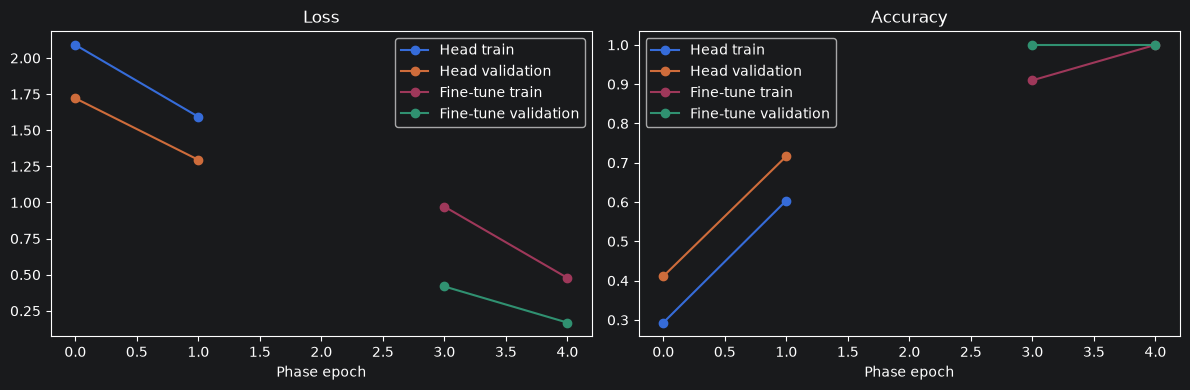

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history["head_train_loss"], marker="o", label="Head train")
axes[0].plot(history["head_val_loss"], marker="o", label="Head validation")
axes[0].plot(
    np.arange(len(history["ft_train_loss"])) + len(history["head_train_loss"]) + 1,
    history["ft_train_loss"], marker="o", label="Fine-tune train"
)
axes[0].plot(
    np.arange(len(history["ft_val_loss"])) + len(history["head_val_loss"]) + 1,
    history["ft_val_loss"], marker="o", label="Fine-tune validation"
)
axes[0].set_title("Loss")
axes[0].set_xlabel("Phase epoch")
axes[0].legend()

axes[1].plot(history["head_train_acc"], marker="o", label="Head train")
axes[1].plot(history["head_val_acc"], marker="o", label="Head validation")
axes[1].plot(
    np.arange(len(history["ft_train_acc"])) + len(history["head_train_acc"]) + 1,
    history["ft_train_acc"], marker="o", label="Fine-tune train"
)
axes[1].plot(
    np.arange(len(history["ft_val_acc"])) + len(history["head_val_acc"]) + 1,
    history["ft_val_acc"], marker="o", label="Fine-tune validation"
)
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Phase epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

## 16. Final test evaluation

Evaluate the selected model on the test set once you have made training decisions using validation data. The test score is an estimate of performance on unseen examples; it is not a guarantee of performance on a different hospital, scanner, population, or image domain.

In [15]:
test_loss, test_accuracy = run_epoch(model, test_loader, criterion)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.3f}")

if not pretrained_loaded:
    print(
        "Caution: pretrained weights were not loaded, so this run demonstrates "
        "the fine-tuning code path rather than successful pretrained transfer learning."
    )
if dataset_source != "CIFAR-10":
    print("Caution: results are from synthetic data and are not scientifically meaningful.")

Test loss: 0.1918
Test accuracy: 1.000
Caution: pretrained weights were not loaded, so this run demonstrates the fine-tuning code path rather than successful pretrained transfer learning.
Caution: results are from synthetic data and are not scientifically meaningful.


## 17. Inspect predictions and confidence

Softmax converts logits into class probabilities. These probabilities can be useful for inspection, but they are not necessarily calibrated confidence estimates.

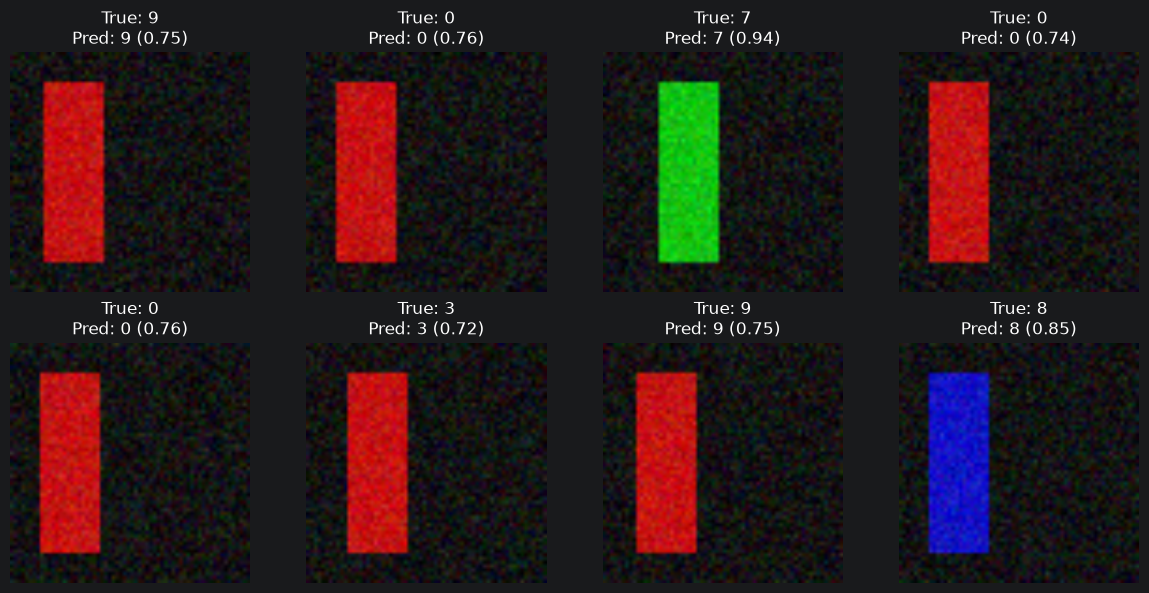

In [16]:
model.eval()
batch_images, batch_labels = next(iter(test_loader))

with torch.no_grad():
    logits = model(batch_images.to(device))
    probabilities = torch.softmax(logits, dim=1)
    predicted_labels = probabilities.argmax(dim=1).cpu()
    confidence = probabilities.max(dim=1).values.cpu()

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    if i < len(batch_images):
        true_label = int(batch_labels[i])
        pred_label = int(predicted_labels[i])
        title_true = class_names[true_label] if dataset_source == "CIFAR-10" else str(true_label)
        title_pred = class_names[pred_label] if dataset_source == "CIFAR-10" else str(pred_label)
        ax.imshow(denormalize_image(batch_images[i]))
        ax.set_title(f"True: {title_true}\nPred: {title_pred} ({confidence[i]:.2f})")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 18. Save and reload a checkpoint

Save the model weights and useful metadata. A `state_dict` is a portable way to store learned parameters. For reproducibility, also record the class names, image size, whether pretrained weights were loaded, and the training configuration.

In [17]:
checkpoint_path = "transfer_learning_resnet18_checkpoint.pth"

checkpoint = {
    "model_state_dict": model.state_dict(),
    "num_classes": num_classes,
    "class_names": class_names,
    "image_size": IMAGE_SIZE,
    "pretrained_weights_loaded": pretrained_loaded,
    "dataset_source": dataset_source,
}
torch.save(checkpoint, checkpoint_path)
print("Saved checkpoint to:", checkpoint_path)

Saved checkpoint to: transfer_learning_resnet18_checkpoint.pth


In [18]:
# Recreate the same architecture before loading its state dictionary.
restored_model = models.resnet18(weights=None)
restored_model.fc = nn.Linear(restored_model.fc.in_features, num_classes)

# Load only the state dictionary into the matching architecture.
try:
    restored_checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=True)
except TypeError:
    # Compatibility fallback for older PyTorch versions without weights_only.
    restored_checkpoint = torch.load(checkpoint_path, map_location=device)

restored_model.load_state_dict(restored_checkpoint["model_state_dict"])
restored_model = restored_model.to(device)
restored_model.eval()
print("Checkpoint restored successfully.")

Checkpoint restored successfully.


## 19. Practical guidance and common mistakes

- **Preprocessing mismatch:** use the normalization expected by the pretrained weights.
- **Wrong output head:** replace the original classifier for the target number of classes.
- **Accidental full training:** explicitly set `requires_grad` to freeze or unfreeze parameters.
- **Learning rate too high:** fine-tuning can overwrite useful pretrained features.
- **Data leakage:** keep test examples out of training and model-selection decisions.
- **Class imbalance:** accuracy can hide poor minority-class performance; inspect per-class recall, precision, F1, and confusion matrices.
- **Domain shift:** natural images and medical images differ. A model pretrained on ImageNet may be a useful baseline, but it may not be the best model for MRI or pathology.
- **Synthetic fallback:** use it only to test the notebook pipeline, never to report model performance.
- **Reproducibility:** record library versions, random seeds, preprocessing, splits, and checkpoint metadata.

## 20. Exercises

1. Compare a frozen backbone with fine-tuning `layer4`. Which parameters changed?
2. Change the learning rate of the classifier and compare validation curves.
3. Unfreeze `layer3` as well as `layer4`; explain the trade-off in trainable parameters and overfitting risk.
4. Add a confusion matrix and per-class precision/recall.
5. Replace CIFAR-10 with a small custom image dataset while preserving a separate test set.
6. Design a domain-specific experiment for medical images. Explain why patient-level splitting is important and why external validation may be needed.
7. Run the notebook once with pretrained weights available and once without them, then compare the difference in what the experiment can legitimately claim.

## 21. Quick Reference

```python
# Load pretrained model
weights = models.ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights)

# Replace the classification head
model.fc = nn.Linear(model.fc.in_features, num_classes)

# Freeze the backbone
for parameter in model.parameters():
    parameter.requires_grad = False

# Train the new head
for parameter in model.fc.parameters():
    parameter.requires_grad = True

# Fine-tune a later block
for parameter in model.layer4.parameters():
    parameter.requires_grad = True

# Use different learning rates for backbone and head
optimizer = torch.optim.AdamW([
    {"params": model.layer4.parameters(), "lr": 1e-5},
    {"params": model.fc.parameters(), "lr": 1e-4},
])

# Save parameters
torch.save(model.state_dict(), "model_state.pth")
```

**Key takeaway:** Start with a frozen pretrained feature extractor as a baseline, then fine-tune selected layers with a smaller learning rate if validation results justify it. Always distinguish real pretrained experiments from fallback runs with random initialization.